# Análisis exploratorio - objetos, expositoras, ciudades y premios

Concursos de tejidos y bordados de Tucumán: **1.º Provincial (1915)** e **Interprovincial (1916)**.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import unicodedata, re, collections

pd.set_option('display.max_rows', 120)
pd.set_option('display.max_colwidth', 70)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'grid.linewidth': .6})

C15, C16 = '#2f4b6e', '#a6323c'   # 1915 / 1916

XLS = RAIZ / 'data' / 'processed' / 'tabla_normalizada.xlsx'
xl = pd.ExcelFile(XLS)
hoja = {s: xl.parse(s) for s in xl.sheet_names}
CAT_SHEET = next(s for s in xl.sheet_names if s.lower().startswith('categor'))

concursos  = hoja['Concursos']
expositoras = hoja['Expositoras']
categorias = hoja[CAT_SHEET].rename(columns={'nombre_categoria': 'categoria'})
ciudades   = hoja['Ciudades']
ciudades = ciudades.rename(columns={'nombre_ciudad_hoy': 'nombre_hoy', 'nombre_provincia': 'provincia'})
objetos    = hoja['Objetos']
premios    = hoja['Premios']

print({s: hoja[s].shape for s in xl.sheet_names})

{'Concursos': (2, 4), 'Expositoras': (464, 3), 'Categorías': (24, 2), 'Ciudades': (77, 10), 'Objetos': (981, 9), 'Premios': (104, 17), 'Fuentes': (4, 8), 'Paginas_Catalogo': (118, 9)}


## 1. Panorama general

In [2]:
anio_de = dict(zip(concursos.concurso_id, concursos.anio))

obj = (objetos
       .merge(ciudades, on='ciudad_id', how='left')
       .merge(categorias[['categoria_id', 'categoria']], on='categoria_id', how='left')
       .merge(expositoras, left_on='expositora_id', right_on='persona_id', how='left'))
obj['anio'] = obj.concurso_id.map(anio_de)

resumen = pd.Series({
    'objetos catalogados'      : len(obj),
    'expositoras (registradas)': expositoras.persona_id.nunique(),
    'expositoras (con objeto)' : objetos.expositora_id.nunique(),
    'localidades'              : ciudades.ciudad_id.nunique(),
    'categorías'               : categorias.categoria_id.nunique(),
    'premios'                  : len(premios),
}, name='total')
resumen.to_frame()

,total
objetos catalogados,981
expositoras (registradas),464
expositoras (con objeto),464
localidades,77
categorías,24
premios,104


In [3]:
# Género de las expositoras (inferido del nombre; instituciones marcadas F por convención)
expositoras['Género'].value_counts(dropna=False)

Género
F    456
M      8
Name: count, dtype: int64

## 2. Los dos concursos

El Interprovincial de 1916 casi **cuadruplica** al Provincial de 1915 y más que duplica
las localidades representadas.

In [4]:
comp = (obj.groupby('anio')
        .agg(objetos=('objeto_id', 'size'),
             expositoras=('expositora_id', 'nunique'),
             localidades=('ciudad_id', 'nunique'),
             categorias=('categoria_id', 'nunique'))
        )
comp

,objetos,expositoras,localidades,categorias
anio,,,,
1915,206,104,29,13
1916,775,388,65,15


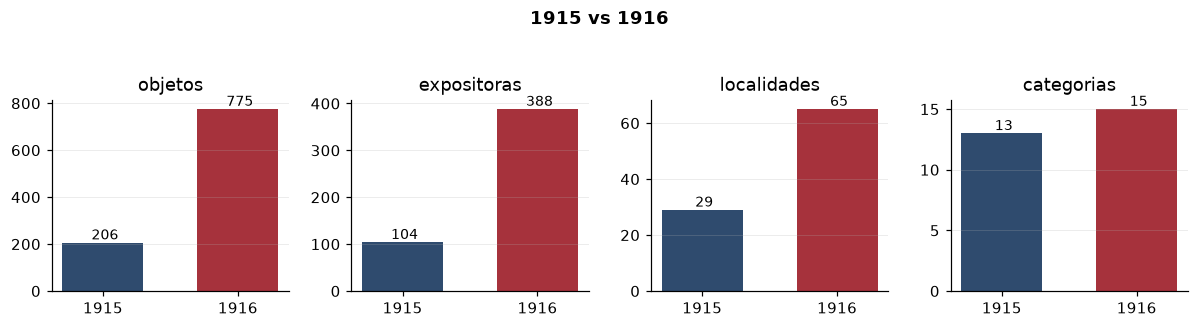

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
for ax, col in zip(axes, comp.columns):
    ax.bar(['1915', '1916'], comp[col], color=[C15, C16], width=.6)
    ax.set_title(col); ax.grid(axis='x')
    for i, v in enumerate(comp[col]):
        ax.text(i, v, f' {v}', ha='center', va='bottom', fontsize=9)
fig.suptitle('1915 vs 1916', y=1.05, fontweight='bold')
plt.tight_layout(); plt.show()

## 3. Objetos por categoría

Las 24 secciones de catálogo **no son las mismas** en los dos años (el jurado reorganizó la
taxonomía): muchas aparecen en un solo año. Aun así, *colchas y frazadas* y *encajes / randas*
concentran más de la mitad del corpus.

In [6]:
piv = (obj.pivot_table(index='categoria', columns='anio', values='objeto_id',
                       aggfunc='count', fill_value=0)
       .rename(columns={1915: 'a1915', 1916: 'a1916'}))
piv['total'] = piv.sum(axis=1)
piv = piv.sort_values('total', ascending=False)
piv

anio,a1915,a1916,total
categoria,,,
COLCHAS Y FRAZADAS,30,189,219
BORDADOS EN BLANCO Y DESHILADOS,0,158,158
ENCAJES Y RANDAS,0,148,148
RANDAS,28,82,110
PONCHOS,5,39,44
ALFOMBRAS,6,22,28
DESHILADO,25,0,25
JERGONES Y SOBREPELOS,0,25,25
CROCHET,24,0,24


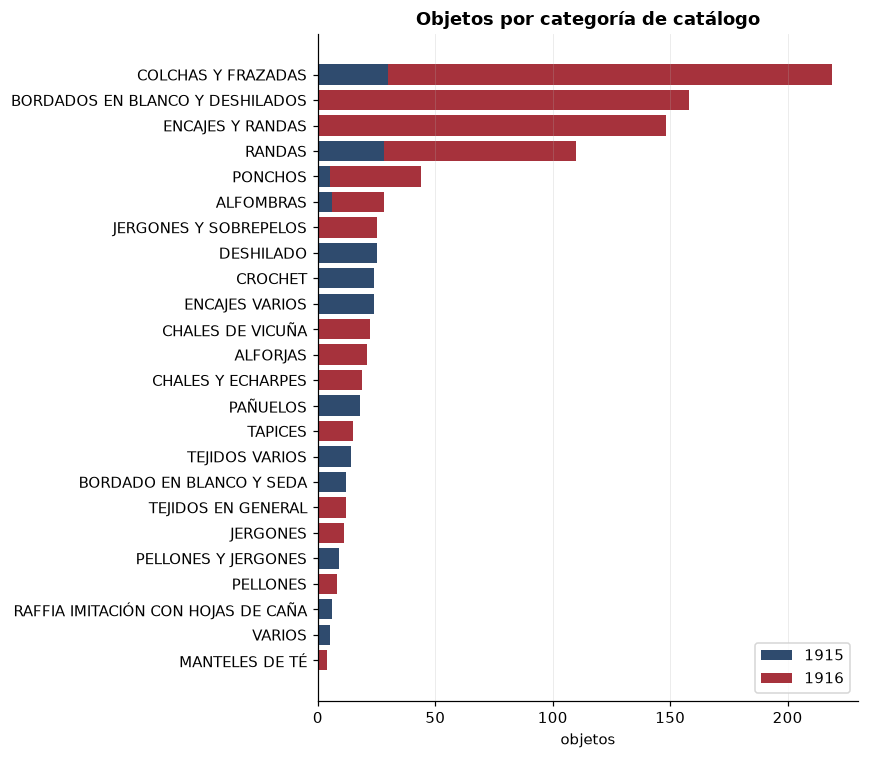

In [7]:
p = piv.sort_values('total')
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(p.index, p['a1915'], color=C15, label='1915')
ax.barh(p.index, p['a1916'], left=p['a1915'], color=C16, label='1916')
ax.set_xlabel('objetos'); ax.legend(); ax.grid(axis='y')
ax.set_title('Objetos por categoría de catálogo', fontweight='bold')
plt.tight_layout(); plt.show()

## 4. Materiales y técnicas

No hay vocabulario controlado: se cuenta la frecuencia de términos en el campo textual `OBJETO`
(un objeto puede sumar a varios). Es el lenguaje del catálogo original.

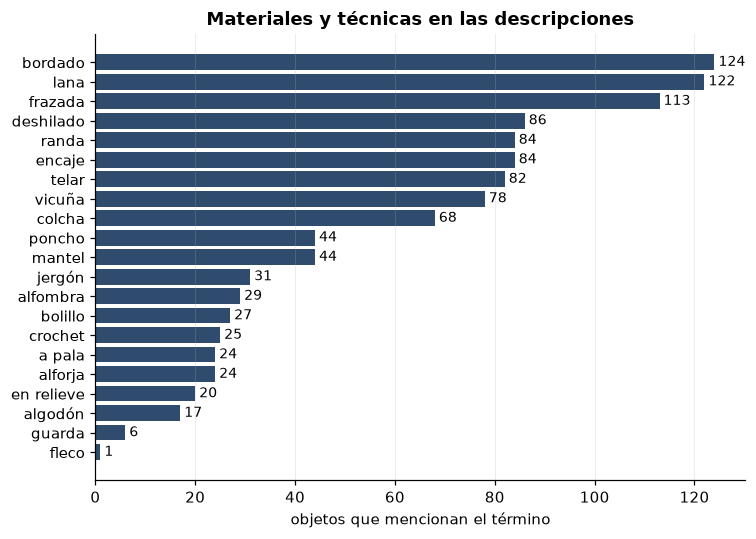

In [8]:
def sin_acentos(s):
    return ''.join(c for c in unicodedata.normalize('NFD', str(s))
                   if unicodedata.category(c) != 'Mn').lower()

TERMINOS = {
    'bordado': r'bordad', 'lana': r'lana', 'frazada': r'frazada', 'colcha': r'colcha',
    'deshilado': r'deshilad', 'encaje': r'encaje', 'randa': r'randa', 'telar': r'telar',
    'vicuña': r'vicu', 'poncho': r'poncho', 'seda': r'seda', 'algodón': r'algod',
    'crochet': r'crochet', 'a pala': r'a pala', 'en relieve': r'relieve', 'jergón': r'jerg',
    'alforja': r'alforja', 'chal': r'chal', 'alfombra': r'alfombra', 'mantel': r'mantel',
    'hilo': r'hilo', 'guarda': r'guarda', 'fleco': r'fleco', 'bolillo': r'bolillo',
}
desc = obj['OBJETO'].map(sin_acentos)
frec = (pd.Series({t: desc.str.contains(p, regex=True).sum() for t, p in TERMINOS.items()})
        .sort_values(ascending=False))
frec = frec[frec > 0]

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(frec.index[::-1], frec.values[::-1], color=C15)
for i, v in enumerate(frec.values[::-1]):
    ax.text(v, i, f' {v}', va='center', fontsize=9)
ax.set_xlabel('objetos que mencionan el término')
ax.set_title('Materiales y técnicas en las descripciones', fontweight='bold')
ax.grid(axis='y'); plt.tight_layout(); plt.show()

In [9]:
# Muestra de descripciones tal cual figuran en la fuente
obj['OBJETO'].dropna().sample(15, random_state=1).tolist()

['poncho a listas',
 'toalla deshilada',
 'frazada tejida de lana',
 'sobrecama bordada',
 'randa, embutidos',
 'pellón de lana',
 'frazada tejida a pala con bordado en relieve',
 'poncho lana tejido en telar',
 'mantel de altar',
 'escote de randa',
 'poncho café de vicuña',
 'Tejido y bordado',
 'tapado en crochet',
 'manta de vicuña',
 'cuellos y puños randa']

## 5. Expositoras

Participación de **cola larga**: la mayoría presenta un solo objeto; la producción es
abrumadoramente **individual y femenina**. Las instituciones (escuelas profesionales, asilos,
hogares de obreras) se detectan por palabra clave en el nombre.

count    464.00
mean       2.11
std        2.71
min        1.00
25%        1.00
50%        1.00
75%        2.00
max       36.00
Name: count, dtype: float64


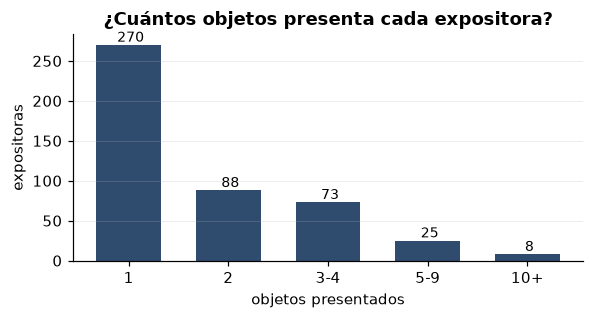

In [10]:
por_expo = objetos.expositora_id.value_counts()
print(por_expo.describe().round(2))

buckets = pd.cut(por_expo, [0, 1, 2, 4, 9, 999], labels=['1', '2', '3-4', '5-9', '10+'])
conteo_buckets = buckets.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5.5, 3))
ax.bar(conteo_buckets.index.astype(str), conteo_buckets.values, color=C15, width=.65)
for i, v in enumerate(conteo_buckets.values):
    ax.text(i, v, f' {v}', ha='center', va='bottom', fontsize=9)
ax.set_xlabel('objetos presentados'); ax.set_ylabel('expositoras'); ax.grid(axis='x')
ax.set_title('¿Cuántos objetos presenta cada expositora?', fontweight='bold')
plt.tight_layout(); plt.show()

In [11]:
ES_INST = re.compile(r'escuela|asilo|hogar|sociedad|soc\.|colegio|taller|ingenio|convento|'
                     r'beneficencia|centro|cooperat', re.I)
expositoras['institucion'] = expositoras['Nombre'].str.contains(ES_INST, na=False)
obj['institucion'] = obj['Nombre'].str.contains(ES_INST, na=False)

pd.DataFrame({
    'expositoras': [(~expositoras.institucion).sum(), expositoras.institucion.sum()],
    'objetos'    : [(~obj.institucion).sum(), obj.institucion.sum()],
}, index=['individuales', 'instituciones'])

,expositoras,objetos
individuales,457,929
instituciones,7,52


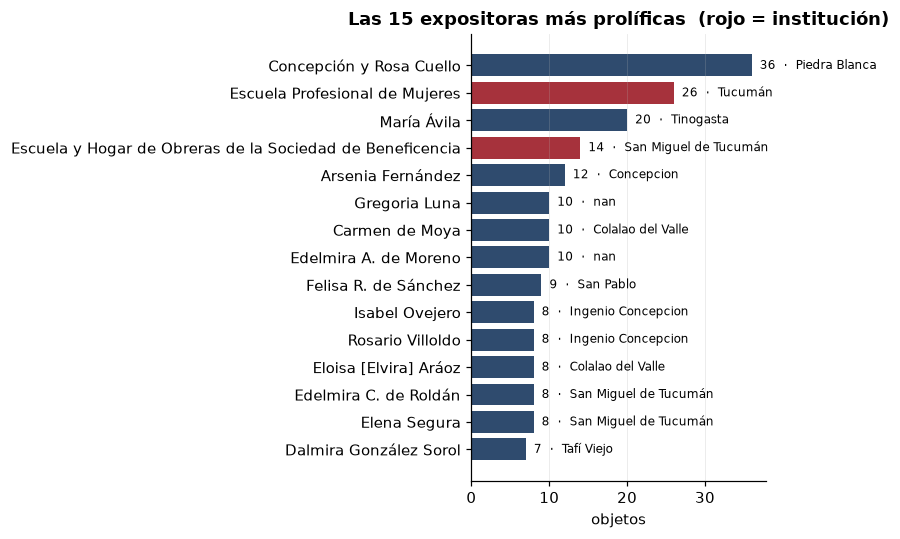

,persona_id,objetos,Nombre,institucion,ciudad
0,25,36,Concepción y Rosa Cuello,False,Piedra Blanca
1,281,26,Escuela Profesional de Mujeres,True,Tucumán
2,115,20,María Ávila,False,Tinogasta
3,102,14,Escuela y Hogar de Obreras de la Sociedad de Beneficencia,True,San Miguel de Tucumán
4,334,12,Arsenia Fernández,False,Concepcion
5,126,10,Gregoria Luna,False,NaN
6,162,10,Carmen de Moya,False,Colalao del Valle
7,244,10,Edelmira A. de Moreno,False,NaN
8,270,9,Felisa R. de Sánchez,False,San Pablo
9,38,8,Isabel Ovejero,False,Ingenio Concepcion


In [12]:
top = (objetos.expositora_id.value_counts().head(15)
       .rename_axis('persona_id').reset_index(name='objetos')
       .merge(expositoras[['persona_id', 'Nombre', 'institucion']], on='persona_id'))
ciudad_de = (obj.dropna(subset=['nombre_ciudad'])
             .groupby('expositora_id')['nombre_ciudad'].first())
top['ciudad'] = top.persona_id.map(ciudad_de)

fig, ax = plt.subplots(figsize=(8, 5))
colores = np.where(top.institucion, C16, C15)
ax.barh(top.Nombre[::-1], top.objetos[::-1], color=colores[::-1])
for i, (v, c) in enumerate(zip(top.objetos[::-1], top.ciudad[::-1])):
    ax.text(v, i, f'  {v}  ·  {c}', va='center', fontsize=8)
ax.set_xlabel('objetos'); ax.grid(axis='y')
ax.set_title('Las 15 expositoras más prolíficas  (rojo = institución)', fontweight='bold')
plt.tight_layout(); plt.show()
top

## 6. Geografía

`lat`/`lon` vienen de `data/interim/decisiones/coordenadas_ciudades.csv` (cargadas a mano
por la investigadora, ver `src/pipeline/04d_coordenadas.py`), no de un diccionario del
notebook. Ciudades sin coordenada cargada quedan sin ubicar.


In [13]:
def norm_key(s):
    s = sin_acentos(s).upper().strip()
    s = re.split(r'[,(?]', s)[0].strip()
    return re.sub(r'\s+', ' ', s)

ciudades['localidad'] = ciudades.nombre_hoy.fillna(ciudades.nombre_ciudad)
ciudades['prov'] = ciudades.provincia

geo = objetos.merge(ciudades, on='ciudad_id', how='left')
geo['anio'] = geo.concurso_id.map(anio_de)
print('objetos con coordenadas:', geo.lat.notna().sum(), 'de', len(geo))


objetos con coordenadas: 756 de 981


In [14]:
# Objetos por provincia (actual)
por_prov = geo.prov.fillna('(sin dato)').value_counts()
por_prov

prov
Tucumán                748
Catamarca              117
Santiago del Estero     47
(sin dato)              41
Salta                   11
Córdoba                  7
Jujuy                    3
Chaco                    3
tucuman o cordoba        2
S/d                      1
La Rioja                 1
Name: count, dtype: int64

In [15]:
por_loc = (geo.assign(loc=geo['localidad'].fillna('(' + geo['prov'].fillna('sin dato') + ', sin localidad)'))
           .groupby('localidad')
           .agg(objetos=('objeto_id', 'size'),
                expositoras=('expositora_id', 'nunique'),
                lat=('lat', 'first'), lon=('lon', 'first'))
           .reset_index()
           .sort_values('objetos', ascending=False))
por_loc.head(20)


,localidad,objetos,expositoras,lat,lon
53,San Miguel de Tucumán,331,169,-26.830373,-65.203917
15,Chicligasta,52,35,-27.434702,-65.163007
42,Monteros,48,28,-27.165476,-65.497536
16,Colalao del Valle,30,7,-26.362041,-65.957014
41,Monteagudo,29,16,-27.511010,-65.277809
44,Orán,24,13,NaN,NaN
64,Tucumán,23,9,NaN,NaN
27,La Cocha,21,13,-27.768819,-65.586022
63,Tinogasta,20,1,-28.062596,-67.566064
7,Atahona,19,15,-27.416744,-65.288219


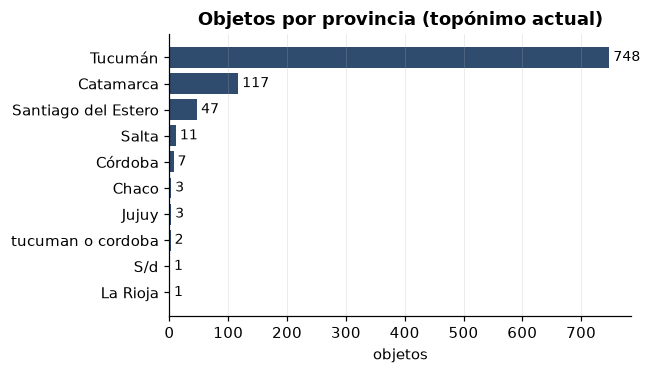

In [16]:
fig, ax = plt.subplots(figsize=(6, 3.5))
p = por_prov[por_prov.index != '(sin dato)'].sort_values()
ax.barh(p.index, p.values, color=C15)
for i, v in enumerate(p.values):
    ax.text(v, i, f' {v}', va='center', fontsize=9)
ax.set_xlabel('objetos'); ax.grid(axis='y')
ax.set_title('Objetos por provincia (topónimo actual)', fontweight='bold')
plt.tight_layout(); plt.show()

### Mapa interactivo (folium)

Si `folium` está instalado (`pip install folium`), genera un mapa navegable con tiles
y lo muestra en la celda. Si no, saltear esta celda.


In [17]:
# El mapa lo genera el pipeline (src/pipeline/05b_mapa.py -> outputs/mapa_procedencias.html),
# así se regenera con cada corrida. Acá sólo se muestra, con los mismos datos.
try:
    import importlib
    from IPython.display import display
    sys.path.insert(0, str(RAIZ / 'src' / 'pipeline'))
    etapa_mapa = importlib.import_module('05b_mapa')
    ciu_pts, prov_pts, sin_ubicar = etapa_mapa.puntos()
    print(len(ciu_pts), 'puntos de ciudad ·', len(prov_pts), 'de provincia ·', sin_ubicar, 'objetos sin ubicar')
    display(etapa_mapa.mapa(ciu_pts, prov_pts))
except ImportError:
    print('folium no instalado — se omite el mapa interactivo')


57 puntos de ciudad · 8 de provincia · 44 objetos sin ubicar


## 7. Premios

premios registrados: 104
sin objeto vinculado: 21


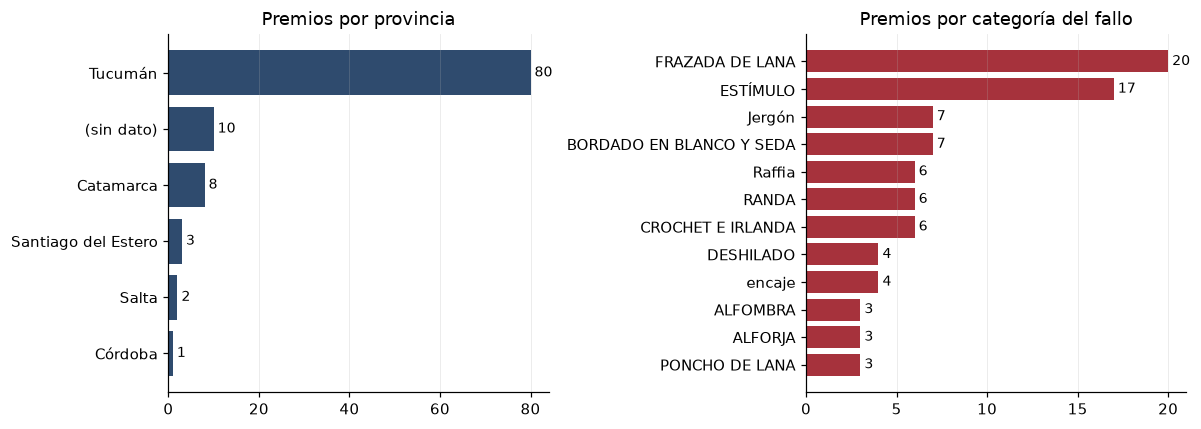

In [18]:
def prov_premio(p):
    return {'TUCUMAN':'Tucumán','CATAMARCA':'Catamarca','SANTIAGO DEL ESTERO':'Santiago del Estero',
            'SALTA':'Salta','CORDOBA':'Córdoba'}.get(norm_key(p)) if pd.notna(p) else None

premios['prov'] = premios['PROVINCIA'].map(prov_premio)
print('premios registrados:', len(premios))
print('sin objeto vinculado:', premios['objeto_id'].isna().sum() if 'objeto_id' in premios else 'n/d')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pp = premios.prov.fillna('(sin dato)').value_counts().sort_values()
axes[0].barh(pp.index, pp.values, color=C15)
axes[0].set_title('Premios por provincia'); axes[0].grid(axis='y')
for i, v in enumerate(pp.values): axes[0].text(v, i, f' {v}', va='center', fontsize=9)

pc = premios['CATEGORÍA'].value_counts().head(12).sort_values()
axes[1].barh(pc.index, pc.values, color=C16)
axes[1].set_title('Premios por categoría del fallo'); axes[1].grid(axis='y')
for i, v in enumerate(pc.values): axes[1].text(v, i, f' {v}', va='center', fontsize=9)
plt.tight_layout(); plt.show()

In [19]:
premios[['PREMIOS', 'NOMBRE', 'CIUDAD', 'PROVINCIA', 'OBJETO', 'CATEGORÍA']].head(20)

,PREMIOS,NOMBRE,CIUDAD,PROVINCIA,OBJETO,CATEGORÍA
0,Premio de 150,Angela L. de Diblasi,Ciudad,TUCUMÁN,tejida en telar con dibujos en el tejido,FRAZADA DE LANA
1,Premio de 150,Petrona Macías,Catamarca,CATAMARCA,tejida a pala y bordado en relieve,FRAZADA DE LANA
2,Premio de 150,Concepción y Rosa Cuello,Catamarca,CATAMARCA,"de lana de vicuña, bordada",FRAZADA DE LANA
3,Premio de 100,Delicia Ruiz,Antofagasta,CATAMARCA,lana de vicuña bordada con seda,FRAZADA DE LANA
4,Premio de 100,Concepción y Rosa Cuello,Catamarca,CATAMARCA,s/d,FRAZADA DE LANA
5,Premio de 50,Rosario Gramajo,Monteagudo,TUCUMÁN,"tejida a pala, con dibujos en relieve",FRAZADA DE LANA
6,Premio de 50,Dominga Castaño,s/d,NaN,frazada,FRAZADA DE LANA
7,Premio de 50,Jesus Rueda,Ciudad,TUCUMÁN,frazada,FRAZADA DE LANA
8,Premio de 50,Vicenta B. de Medina,Chicligasta,TUCUMÁN,frazada,FRAZADA DE LANA
9,Premio de 50,María Juarez,Yacuchiri,TUCUMÁN,frazada,FRAZADA DE LANA


## 8. Notas y limitaciones

- **Normalización de localidades incompleta.** 21 de 77 ciudades no tienen `nombre_hoy` resuelto;
  ~125 objetos sólo tienen provincia (92 «Catamarca», 33 «Santiago del Estero»).
- **Taxonomía de categorías no unificada** entre 1915 y 1916 — comparar por familia de objeto,
  no por sección de catálogo.
- **Género inferido** del nombre de pila; instituciones marcadas F por convención.
- **Orán sin ubicar:** puede ser el de Tucumán o el de Salta (LM 9-10); queda sin punto y sin provincia.
- **Geolocalización:** `lat`/`lon` y el punto de provincia viven en
  `data/interim/decisiones/coordenadas_ciudades.csv` (etapa `04d`); el mapa lo genera
  la etapa `05b_mapa`. Lo que sólo tiene provincia se ubica en la capital.
- **Premios:** el campo `PREMIOS` mezcla monto y tipo; hay premios sin objeto vinculado.